# GTSRB — simple 43-class CNN

End-to-end CNN: raw `48×48` RGB crops → 43-way softmax.

- Same track-aware train/val split (`artifacts/split.json`)
- Augmentation without horizontal flips
- Balanced sampling for class imbalance
- Best checkpoint by validation `min_critical_recall`
- **Official test is not used**

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, recall_score
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision.datasets import GTSRB
from torchvision.transforms import v2

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})

SEED = 42
N_CLASSES = 43
IMG = 48
EPOCHS = 30
BATCH = 128
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available()
    else ("cuda" if torch.cuda.is_available() else "cpu")
)
print(f"device: {DEVICE}")

SIGN_NAMES = {
    0: "Speed limit (20km/h)", 1: "Speed limit (30km/h)", 2: "Speed limit (50km/h)",
    3: "Speed limit (60km/h)", 4: "Speed limit (70km/h)", 5: "Speed limit (80km/h)",
    6: "End of speed limit (80km/h)", 7: "Speed limit (100km/h)", 8: "Speed limit (120km/h)",
    9: "No passing", 10: "No passing for vehicles over 3.5 metric tons",
    11: "Right-of-way at the next intersection", 12: "Priority road", 13: "Yield", 14: "Stop",
    15: "No vehicles", 16: "Vehicles over 3.5 metric tons prohibited", 17: "No entry",
    18: "General caution", 19: "Dangerous curve to the left", 20: "Dangerous curve to the right",
    21: "Double curve", 22: "Bumpy road", 23: "Slippery road", 24: "Road narrows on the right",
    25: "Road work", 26: "Traffic signals", 27: "Pedestrians", 28: "Children crossing",
    29: "Bicycles crossing", 30: "Beware of ice/snow", 31: "Wild animals crossing",
    32: "End of all speed and passing limits", 33: "Turn right ahead", 34: "Turn left ahead",
    35: "Ahead only", 36: "Go straight or right", 37: "Go straight or left", 38: "Keep right",
    39: "Keep left", 40: "Roundabout mandatory", 41: "End of no passing",
    42: "End of no passing by vehicles over 3.5 metric tons",
}
CRITICAL_CLASSES = [13, 14, 17]
SPEED_BLOCK = list(range(9))
CRITICAL_SET = sorted(set(CRITICAL_CLASSES) | set(SPEED_BLOCK))

train_ds = GTSRB(root="data", split="train", download=True)
paths = [p for p, _ in train_ds._samples]
y_all = np.array([int(t) for _, t in train_ds._samples])

with open(ARTIFACTS / "split.json") as f:
    split = json.load(f)
train_idx = np.array(split["train_idx"])
val_idx = np.array(split["val_idx"])
print(f"train {len(train_idx):,}   val {len(val_idx):,}")

device: mps
train 21,360   val 5,280


## 1. Pixel cache (48×48) for train + val indices

In [2]:
PIX_CACHE = ARTIFACTS / "pixels48_all_train.npz"
needed = np.unique(np.concatenate([train_idx, val_idx]))


def load48(path: str) -> np.ndarray:
    with Image.open(path) as im:
        return np.asarray(im.convert("RGB").resize((IMG, IMG), Image.BILINEAR), dtype=np.uint8)


if PIX_CACHE.exists():
    pc = np.load(PIX_CACHE)
    assert np.array_equal(pc["idx"], needed)
    PIX = pc["X"]
    print(f"Loaded pixel cache {PIX.shape}")
else:
    PIX = np.stack([load48(paths[i]) for i in needed])
    np.savez_compressed(PIX_CACHE, idx=needed, X=PIX)
    print(f"Built pixel cache {PIX.shape} -> {PIX_CACHE}")

prow = {int(gi): r for r, gi in enumerate(needed)}
pix_train = PIX[[prow[int(i)] for i in train_idx]]
pix_val = PIX[[prow[int(i)] for i in val_idx]]
y_train = y_all[train_idx]
y_val = y_all[val_idx]

MEAN = (pix_train.astype(np.float32) / 255.0).mean(axis=(0, 1, 2))
STD = (pix_train.astype(np.float32) / 255.0).std(axis=(0, 1, 2))
print(f"mean {MEAN.round(3)}, std {STD.round(3)}")

Loaded pixel cache (26640, 48, 48, 3)


mean [0.282 0.254 0.264], std [0.259 0.25  0.257]


## 2. Dataset, model, loaders

In [3]:
class PixelDataset(Dataset):
    def __init__(self, pixels: np.ndarray, labels: np.ndarray, transform):
        self.pixels = torch.from_numpy(pixels).permute(0, 3, 1, 2).contiguous()
        self.labels = torch.from_numpy(labels).long()
        self.transform = transform

    def __len__(self):
        return len(self.pixels)

    def __getitem__(self, i):
        return self.transform(self.pixels[i]), self.labels[i]


norm = v2.Compose([
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=MEAN.tolist(), std=STD.tolist()),
])
train_tf = v2.Compose([
    v2.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    v2.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.2),
    norm,
])


class SimpleCNN43(nn.Module):
    def __init__(self, n_out: int = N_CLASSES):
        super().__init__()

        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU(inplace=True),
                nn.Conv2d(cout, cout, 3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            )

        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))  # 48 -> 6
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128 * 6 * 6, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, n_out),
        )

    def forward(self, x):
        return self.head(self.features(x))


counts = np.bincount(y_train, minlength=N_CLASSES)
sample_w = (1.0 / counts)[y_train]
sampler = WeightedRandomSampler(
    torch.from_numpy(sample_w).double(),
    num_samples=len(sample_w),
    replacement=True,
    generator=torch.Generator().manual_seed(SEED),
)

train_loader = DataLoader(
    PixelDataset(pix_train, y_train, train_tf),
    batch_size=BATCH,
    sampler=sampler,
    num_workers=0,
)
val_loader = DataLoader(
    PixelDataset(pix_val, y_val, norm),
    batch_size=512,
    shuffle=False,
    num_workers=0,
)

model = SimpleCNN43().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"SimpleCNN43 parameters: {n_params:,}")

SimpleCNN43 parameters: 1,478,859


## 3. Train — select best epoch by val `min_critical_recall`

In [4]:
def adas_report(y_true, y_pred, name="model"):
    per = recall_score(y_true, y_pred, labels=list(range(N_CLASSES)), average=None, zero_division=0)
    critical = {c: per[c] for c in CRITICAL_SET}
    worst = int(np.argmin([critical[c] for c in CRITICAL_SET]))
    return {
        "model": name,
        "min_critical_recall": float(min(critical.values())),
        "mean_critical_recall": float(np.mean(list(critical.values()))),
        "stop_recall": float(per[14]),
        "yield_recall": float(per[13]),
        "no_entry_recall": float(per[17]),
        "speed_block_mean_recall": float(np.mean(per[SPEED_BLOCK])),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "worst_critical_class": f"{CRITICAL_SET[worst]} ({SIGN_NAMES[CRITICAL_SET[worst]]})",
    }


@torch.no_grad()
def predict_loader(model, loader):
    model.eval()
    preds, targets = [], []
    for x, t in loader:
        preds.append(model(x.to(DEVICE)).argmax(1).cpu().numpy())
        targets.append(t.numpy())
    return np.concatenate(preds), np.concatenate(targets)


@torch.no_grad()
def mean_loss(model, loader, loss_fn):
    model.eval()
    total, n = 0.0, 0
    for x, t in loader:
        x, t = x.to(DEVICE), t.to(DEVICE)
        total += loss_fn(model(x), t).item() * len(t)
        n += len(t)
    return total / n


opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
loss_fn = nn.CrossEntropyLoss()

# Augmentation and dropout inflate the running training loss, so it cannot be
# compared with the clean validation loss. This un-augmented train subsample is
# the same size as the validation set, making the train/val gap meaningful.
clean_idx = np.random.default_rng(SEED).choice(len(y_train), len(y_val), replace=False)
clean_train_loader = DataLoader(
    PixelDataset(pix_train[clean_idx], y_train[clean_idx], norm),
    batch_size=512,
    shuffle=False,
    num_workers=0,
)

best_key = (-1.0, -1.0, -1.0)  # min_crit, mean_crit, macro_f1
best_state = None
best_epoch = 0
history = []

for epoch in range(EPOCHS):
    model.train()
    running = 0.0
    for x, t in train_loader:
        x, t = x.to(DEVICE), t.to(DEVICE)
        opt.zero_grad()
        loss = loss_fn(model(x), t)
        loss.backward()
        opt.step()
        running += loss.item() * len(t)
    sched.step()

    vp, vt = predict_loader(model, val_loader)
    rep = adas_report(vt, vp)
    val_loss = mean_loss(model, val_loader, loss_fn)
    train_loss_clean = mean_loss(model, clean_train_loader, loss_fn)
    key = (rep["min_critical_recall"], rep["mean_critical_recall"], rep["macro_f1"])
    history.append({
        "epoch": epoch + 1,
        "train_loss_aug": running / len(y_train),
        "train_loss_clean": train_loss_clean,
        "val_loss": val_loss,
        "val_acc": rep["accuracy"],
        "min_critical_recall": rep["min_critical_recall"],
        "macro_f1": rep["macro_f1"],
    })
    marker = ""
    if key > best_key:
        best_key = key
        best_epoch = epoch + 1
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        marker = " *"
    print(
        f"epoch {epoch + 1:>2}/{EPOCHS}  loss {running / len(y_train):.4f}  "
        f"train_loss {train_loss_clean:.4f}  val_loss {val_loss:.4f}  "
        f"val_acc {rep['accuracy']:.4f}  min_crit {rep['min_critical_recall']:.4f}  "
        f"macro_f1 {rep['macro_f1']:.4f}{marker}"
    )

model.load_state_dict(best_state)
torch.save(
    {
        "state_dict": best_state,
        "mean": MEAN.tolist(),
        "std": STD.tolist(),
        "img": IMG,
        "best_epoch": best_epoch,
    },
    ARTIFACTS / "simple_cnn_43.pt",
)
pd.DataFrame(history).to_csv(ARTIFACTS / "simple_cnn_43_history.csv", index=False)
print(f"\nBest min_critical_recall = {best_key[0]:.4f} at epoch {best_epoch}")
print("weights -> artifacts/simple_cnn_43.pt   history -> artifacts/simple_cnn_43_history.csv")

epoch  1/30  loss 2.4260  train_loss 0.8739  val_loss 1.2708  val_acc 0.6019  min_crit 0.0167  macro_f1 0.5534 *


epoch  2/30  loss 0.6997  train_loss 0.2620  val_loss 0.5418  val_acc 0.8074  min_crit 0.2458  macro_f1 0.8052 *


epoch  3/30  loss 0.3010  train_loss 0.0670  val_loss 0.2461  val_acc 0.9187  min_crit 0.7467  macro_f1 0.9093 *


epoch  4/30  loss 0.1595  train_loss 0.0413  val_loss 0.1514  val_acc 0.9502  min_crit 0.9000  macro_f1 0.9319 *


epoch  5/30  loss 0.1102  train_loss 0.0236  val_loss 0.1070  val_acc 0.9636  min_crit 0.8250  macro_f1 0.9660


epoch  6/30  loss 0.0862  train_loss 0.0196  val_loss 0.1660  val_acc 0.9447  min_crit 0.8444  macro_f1 0.9371


... (21 outputs left out)

epoch 28/30  loss 0.0051  train_loss 0.0001  val_loss 0.0296  val_acc 0.9928  min_crit 0.9875  macro_f1 0.9854 *


epoch 29/30  loss 0.0038  train_loss 0.0001  val_loss 0.0299  val_acc 0.9926  min_crit 0.9792  macro_f1 0.9859


epoch 30/30  loss 0.0031  train_loss 0.0001  val_loss 0.0305  val_acc 0.9922  min_crit 0.9792  macro_f1 0.9848



Best min_critical_recall = 0.9875 at epoch 28
weights -> artifacts/simple_cnn_43.pt   history -> artifacts/simple_cnn_43_history.csv


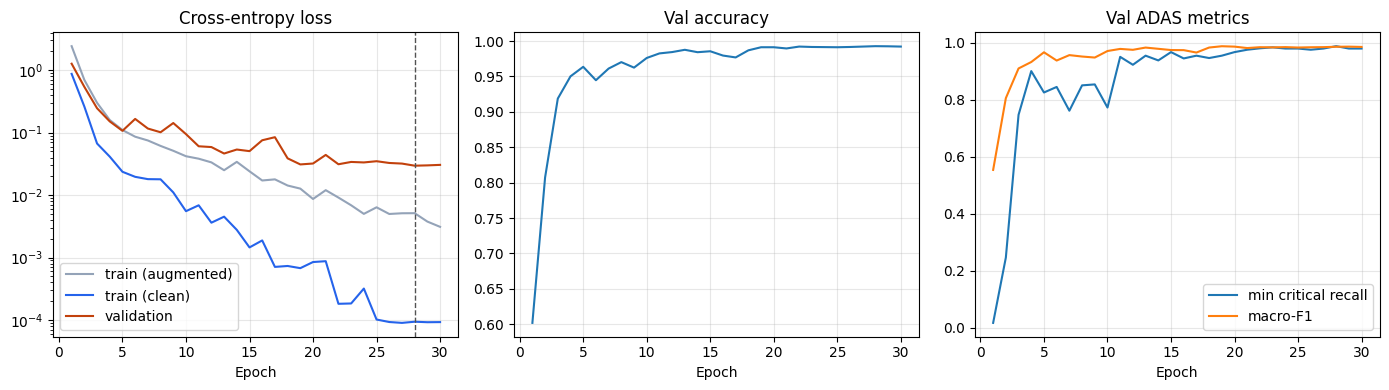

final train loss 0.0001  final val loss 0.0305  gap 0.0304
minimum val loss 0.0296 at epoch 28


In [5]:
hist = pd.DataFrame(history)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(hist["epoch"], hist["train_loss_aug"], label="train (augmented)", color="#94a3b8")
axes[0].plot(hist["epoch"], hist["train_loss_clean"], label="train (clean)", color="#2563eb")
axes[0].plot(hist["epoch"], hist["val_loss"], label="validation", color="#c2410c")
axes[0].axvline(best_epoch, color="#525252", linestyle="--", linewidth=1)
axes[0].set_yscale("log")
axes[0].set_title("Cross-entropy loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(hist["epoch"], hist["val_acc"])
axes[1].set_title("Val accuracy"); axes[1].set_xlabel("Epoch")
axes[2].plot(hist["epoch"], hist["min_critical_recall"], label="min critical recall")
axes[2].plot(hist["epoch"], hist["macro_f1"], label="macro-F1")
axes[2].set_title("Val ADAS metrics"); axes[2].set_xlabel("Epoch"); axes[2].legend()
fig.tight_layout()
plt.show()

gap = hist["val_loss"] - hist["train_loss_clean"]
print(f"final train loss {hist['train_loss_clean'].iloc[-1]:.4f}  "
      f"final val loss {hist['val_loss'].iloc[-1]:.4f}  gap {gap.iloc[-1]:.4f}")
print(f"minimum val loss {hist['val_loss'].min():.4f} at epoch {int(hist.loc[hist['val_loss'].idxmin(), 'epoch'])}")

## 4. Validation metrics vs flat-pixel baseline

In [6]:
pred_val, y_true = predict_loader(model, val_loader)
rep = adas_report(y_true, pred_val, "Simple CNN 43-way @48")

# Compare to flat baseline CSV if present
rows = [rep]
flat_csv = ARTIFACTS / "flat_pixel_baseline_val.csv"
if flat_csv.exists():
    flat = pd.read_csv(flat_csv)
    for _, r in flat.iterrows():
        rows.append(r.to_dict())

comparison = pd.DataFrame(rows).set_index("model")
comparison.to_csv(ARTIFACTS / "simple_cnn_43_val.csv")
comparison.round(4)

,min_critical_recall,mean_critical_recall,stop_recall,yield_recall,no_entry_recall,speed_block_mean_recall,macro_f1,accuracy,worst_critical_class
model,,,,,,,,,
Simple CNN 43-way @48,0.9875,0.9968,1.0000,0.9900,1.00,0.9969,0.9854,0.9928,5 (Speed limit (80km/h))
Flattened pixels / logistic regression (SGD),0.2000,0.6278,0.9333,0.7967,0.96,0.5382,0.5837,0.6345,8 (Speed limit (120km/h))
Flattened pixels / linear SVM (SGD hinge),0.2167,0.6354,0.9333,0.8033,0.96,0.5476,0.5910,0.6388,8 (Speed limit (120km/h))


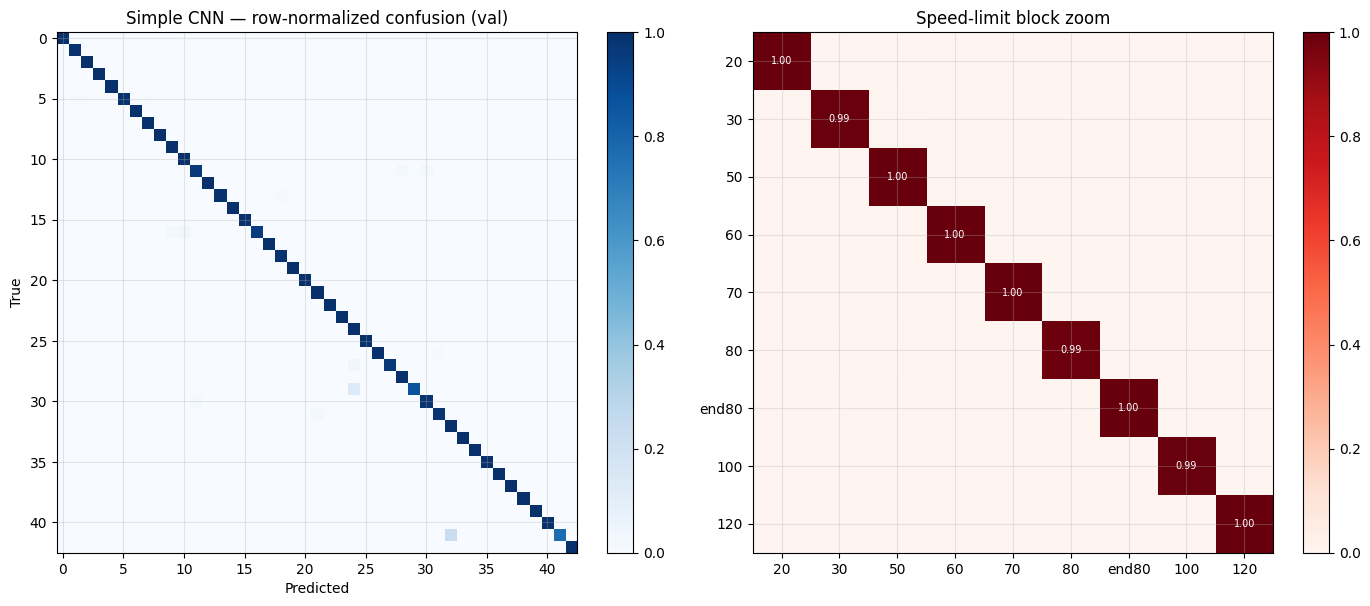

Worst 8 classes on val:


,SignName,recall
41,End of no passing,0.767
29,Bicycles crossing,0.867
16,Vehicles over 3.5 metric tons prohibited,0.950
11,Right-of-way at the next intersection,0.961
27,Pedestrians,0.967
30,Beware of ice/snow,0.983
31,Wild animals crossing,0.983
18,General caution,0.987


In [7]:
cm = confusion_matrix(y_true, pred_val, labels=list(range(N_CLASSES)))
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
im0 = axes[0].imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
axes[0].set_title("Simple CNN — row-normalized confusion (val)")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")
fig.colorbar(im0, ax=axes[0], fraction=0.046)

speed = cm_norm[np.ix_(SPEED_BLOCK, SPEED_BLOCK)]
im1 = axes[1].imshow(speed, cmap="Reds", vmin=0, vmax=1)
axes[1].set_title("Speed-limit block zoom")
labels_short = ["20", "30", "50", "60", "70", "80", "end80", "100", "120"]
axes[1].set_xticks(range(9)); axes[1].set_yticks(range(9))
axes[1].set_xticklabels(labels_short); axes[1].set_yticklabels(labels_short)
for r in range(9):
    for c in range(9):
        if speed[r, c] > 0.01:
            axes[1].text(c, r, f"{speed[r, c]:.2f}", ha="center", va="center", fontsize=7,
                         color="white" if speed[r, c] > 0.5 else "black")
fig.colorbar(im1, ax=axes[1], fraction=0.046)
fig.tight_layout()
plt.show()

per = recall_score(y_true, pred_val, labels=range(N_CLASSES), average=None, zero_division=0)
print("Worst 8 classes on val:")
pd.DataFrame({
    "SignName": [SIGN_NAMES[c] for c in range(N_CLASSES)],
    "recall": per.round(3),
}).sort_values("recall").head(8)

### Notes

- This is a single flat 43-way CNN — no hierarchy.
- Checkpoint chosen by ADAS ordering on validation, not overall accuracy alone.
- Weights: `artifacts/simple_cnn_43.pt`. Official test remains unused.